## Packages

In [33]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt 
import seaborn as sns
sns.set()

In [3]:
raw_data = pd.read_csv('data/students.csv')
raw_data

,StudentID,Name,Grade,AttendedRemedialClass
0,4001,Student_1,89,0
1,4002,Student_2,72,0
2,4003,Student_3,76,1
3,4004,Student_4,89,1
4,4005,Student_5,74,1
...,...,...,...,...
95,4096,Student_96,93,0
96,4097,Student_97,92,0
97,4098,Student_98,99,1
98,4099,Student_99,97,0


## Variables

In [29]:
y = raw_data['AttendedRemedialClass'] # Dependent variable
x1 = raw_data['Grade'] # Independent Variable

## Plotting

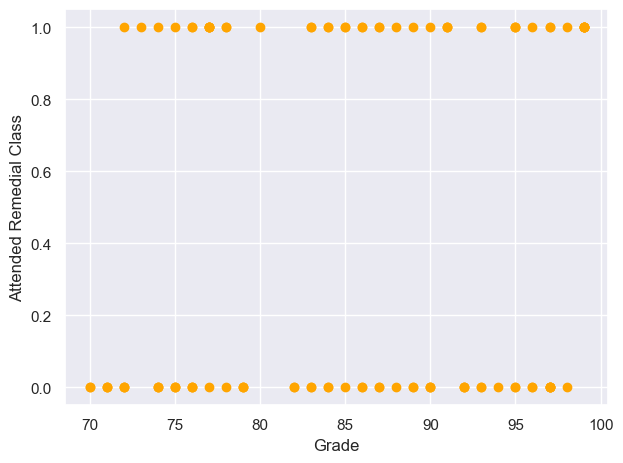

In [24]:
plt.scatter(x1,y,color ='Orange')
plt.xlabel("Grade", fontsize = 12)
plt.ylabel('Attended Remedial Class', fontsize = 12)
plt.tight_layout()
plt.show()

## Plot Linear Regression

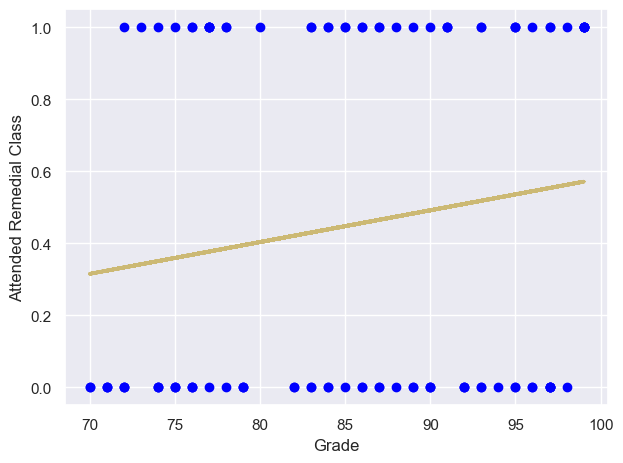

In [27]:
x = sm.add_constant(x1)
reg_lin = sm.OLS(y,x)
results_lin = reg_lin.fit()

plt.scatter(x1,y, color = 'Blue')
y_hat = x1 * results_lin.params.iloc[1] + results_lin.params.iloc[0]

plt.plot(x1,y_hat,lw=2.5, color = 'C8')
plt.xlabel('Grade', fontsize = 12)
plt.ylabel('Attended Remedial Class', fontsize = 12)
plt.tight_layout()
plt.show()

## Plot with a Logistic Regression Curve

Optimization terminated successfully.
         Current function value: 0.675455
         Iterations 4


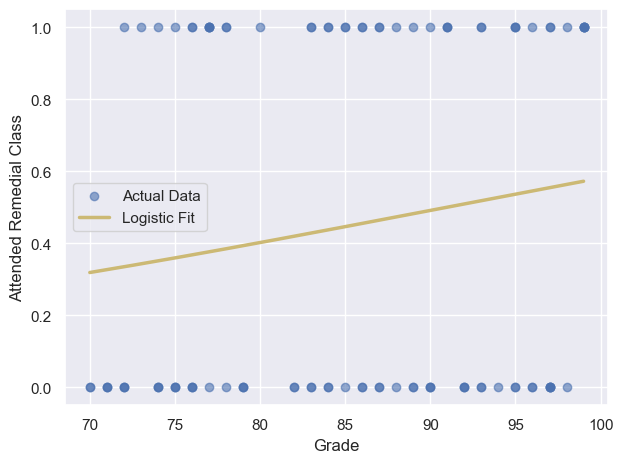

In [30]:
# Fit the Logit model
x = sm.add_constant(x1)
reg_log = sm.Logit(y, x)
results_log = reg_log.fit()

# 1. Plot the actual scatter data
plt.scatter(x1, y, color='C0', alpha=0.6, label='Actual Data')

# 2. FIX: Generate a smooth range of X values for a clean S-curve
x1_smooth = np.linspace(x1.min(), x1.max(), 300)
x_smooth = sm.add_constant(x1_smooth)

# 3. FIX: Use the built-in predict method to get probabilities
y_prob = results_log.predict(x_smooth)

# 4. Plot the smooth Logistic Regression curve
plt.plot(x1_smooth, y_prob, color='C8', lw=2.5, label='Logistic Fit')

# Formatting
plt.xlabel('Grade', fontsize=12)
plt.ylabel('Attended Remedial Class', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
print(results_log.summary())

                             Logit Regression Results                            
Dep. Variable:     AttendedRemedialClass   No. Observations:                  100
Model:                             Logit   Df Residuals:                       98
Method:                              MLE   Df Model:                            1
Date:                   Thu, 15 Oct 2026   Pseudo R-squ.:                 0.01843
Time:                           01:23:50   Log-Likelihood:                -67.546
converged:                          True   LL-Null:                       -68.814
Covariance Type:               nonrobust   LLR p-value:                    0.1112
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.2953      1.979     -1.665      0.096      -7.174       0.584
Grade          0.0362      0.023      1.575      0.115      -0.009       0.081
